# CP3 · Segmentació de clients i accions

**Objectiu:** descriure perfils de client que ajuden a decidir campanyes, serveis o prioritats comercials.

Ens basem en `customers.csv`: una fotografia de 2.000 clients a 30/06/2026 (una fila = un client).

## 1. Preparació

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Llegim el fitxer de clients
df = pd.read_csv('../dades/customers.csv')

print(df.shape)
df.head()

(2000, 14)


,customer_id,age,city,channel_preference,annual_spend,avg_order_value,orders_last_12m,returns_ratio,bike_interest,service_interest,snapshot_date,tenure_months,days_since_last_order,returned_orders_last_12m
0,C00001,48.0,Alzira,store,4566.25,913.25,5,0.0000,electric,low,2026-06-30,67,54.0,0
1,C00002,38.0,Carcaixent,store,3835.08,639.18,6,0.0000,electric,low,2026-06-30,95,23.0,0
2,C00003,43.0,Gandia,store,1159.47,128.83,9,0.0000,urban,medium,2026-06-30,9,1.0,0
3,C00004,59.0,Carcaixent,store,2702.07,300.23,9,0.1111,electric,low,2026-06-30,79,84.0,1
4,C00005,18.0,Gandia,ecommerce,304.05,101.35,3,0.0000,electric,low,2026-06-30,89,73.0,0


### 1.1 Nuls i duplicats

In [2]:
# Quants nuls hi ha en cada columna
print(df.isnull().sum())

# Quantes files estan duplicades
print('Files duplicades:', df.duplicated().sum())

customer_id                  0
age                         20
city                         0
channel_preference           0
annual_spend                30
avg_order_value              0
orders_last_12m              0
returns_ratio                0
bike_interest                0
service_interest             0
snapshot_date                0
tenure_months                0
days_since_last_order       20
returned_orders_last_12m     0
dtype: int64
Files duplicades: 0


**Decisions:**

- `annual_spend` (30 nuls): és **tiquet mitjà × comandes**, així que es pot **recalcular** exactament (es comprova ací baix). No imputem amb 0 ni amb la mitjana.
- `days_since_last_order` (20 nuls): un `0` voldria dir «ha comprat hui», que és un valor real, així que **no** posem 0. Com que és una variable del clustering i només són el 1 %, **excloem eixes 20 files** del clustering.
- `age` (20 nuls): no la usem per a segmentar. La deixem tal qual i només la fem servir per a descriure els perfils.

In [ ]:
# annual_spend = tiquet mitjà x comandes
calc = df['avg_order_value'] * df['orders_last_12m']
calc = calc.round(2)

# Comprovem que el càlcul coincideix amb els valors que ja tenim (ha de donar 0)
print('Diferència màxima:', (calc - df['annual_spend']).abs().max())

# Omplim els nuls d'annual_spend amb el valor calculat
df['annual_spend'] = df['annual_spend'].fillna(calc)
print('Nuls que queden:', df['annual_spend'].isnull().sum())

# No cal llevar age

Diferència màxima: 0.0
Nuls que queden: 0


### 1.2 Valors extrems i distribucions

       days_since_last_order  orders_last_12m  avg_order_value  returns_ratio
count            1980.000000      2000.000000      2000.000000    2000.000000
mean               71.826263         5.245500       254.910830       0.065912
std                80.338207         2.985412       266.428299       0.133173
min                 0.000000         1.000000        19.060000       0.000000
25%                17.000000         3.000000        93.955000       0.000000
50%                44.000000         5.000000       145.560000       0.000000
75%                95.000000         7.000000       289.390000       0.100000
max               364.000000        17.000000      1898.820000       1.000000


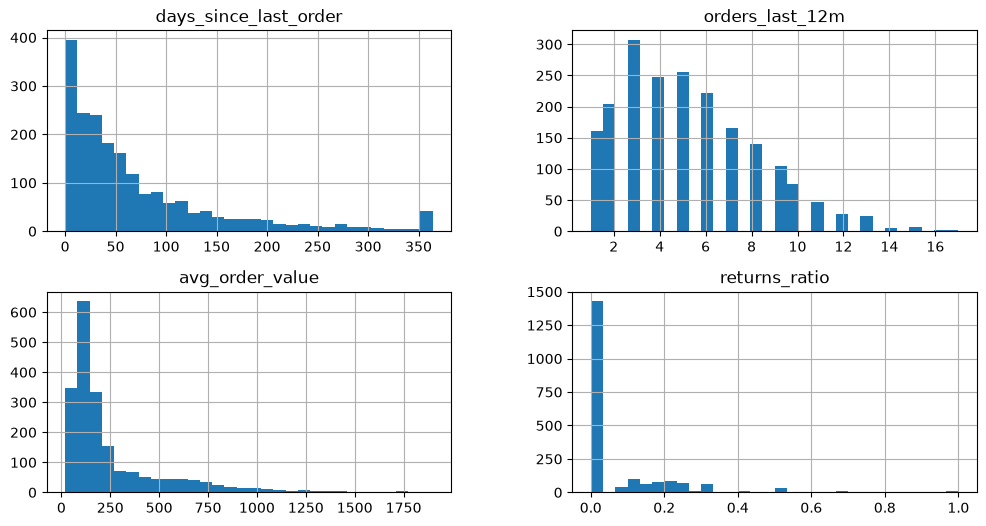

Asimetria de avg_order_value: 2.24


In [4]:
# Les 4 variables que mirarem
cols = ['days_since_last_order', 'orders_last_12m', 'avg_order_value', 'returns_ratio']

# Resum: mitjana, mínim, màxim...
print(df[cols].describe())

# Un histograma per a cada variable
df[cols].hist(bins=30, figsize=(12, 6))
plt.show()

# Asimetria: si és molt major que 1, hi ha una cua llarga a la dreta
print('Asimetria de avg_order_value:', round(df['avg_order_value'].skew(), 2))

`avg_order_value` té una cua llarga cap a la dreta (clients amb tiquets de més de 1.000 €). **Decisió:** no eliminem eixos clients, perquè són precisament els que interessen a l'empresa. Apliquem `log` al tiquet mitjà perquè no dominen el K-Means. La resta de variables es queden com estan.

### 1.3 Variables del clustering

| Variable | Decisió | Motiu |
|---|---|---|
| `days_since_last_order` | **Usada** | Recència |
| `orders_last_12m` | **Usada** | Freqüència |
| `avg_order_value` (en log) | **Usada** | Valor de cada compra |
| `returns_ratio` | **Usada** | Devolucions |
| `annual_spend` | **Descartada** | És tiquet mitjà × comandes: usar les tres donaria massa pes al mateix comportament |
| `returned_orders_last_12m` | Descartada | Redundant amb `returns_ratio` i `orders_last_12m` |
| `customer_id`, `snapshot_date` | **Excloses** | Identificador i data de la fotografia, no descriuen comportament |
| `age`, `city`, `channel_preference`, `bike_interest`, `service_interest`, `tenure_months` | Només per a descriure | Les mirem després per a interpretar els perfils |

In [5]:
# Logaritme del tiquet mitjà (fa més xicoteta la cua llarga)
df['log_avg_order_value'] = np.log(df['avg_order_value'])

# Les variables que usarem per a crear els grups
vars_cluster = ['days_since_last_order', 'orders_last_12m',
                'log_avg_order_value', 'returns_ratio']

# Traiem les files que no tenen recència (20 clients)
d = df.dropna(subset=['days_since_last_order']).copy()
print('Clients al clustering:', len(d))

# Escalem: cada variable queda amb mitjana 0 i desviació 1
# Així cap variable pesa més només per tindre números més grans
X = StandardScaler().fit_transform(d[vars_cluster])

Clients al clustering: 1980


## 2. Tècnica

### 2.1 Primera referència: segmentació per regles

Regles senzilles sobre les mateixes dades.

In [6]:
# Regles senzilles: a cada client li posem una etiqueta
def regla(fila):
    if fila['returns_ratio'] >= 0.25:
        return 'Devolucions altes'
    if fila['days_since_last_order'] > 180:
        return 'Inactius'
    if fila['orders_last_12m'] >= 7 and fila['avg_order_value'] >= 150:
        return 'Valuosos'
    return 'Resta'

# Apliquem la funció a cada fila (axis=1)
d['segment_regles'] = d.apply(regla, axis=1)

# Quants clients té cada etiqueta
d['segment_regles'].value_counts()

segment_regles
Resta                1235
Valuosos              361
Devolucions altes     206
Inactius              178
Name: count, dtype: int64

### 2.2 K-Means

Provem diversos valors de k i mirem la inèrcia (colze) i el *silhouette*.

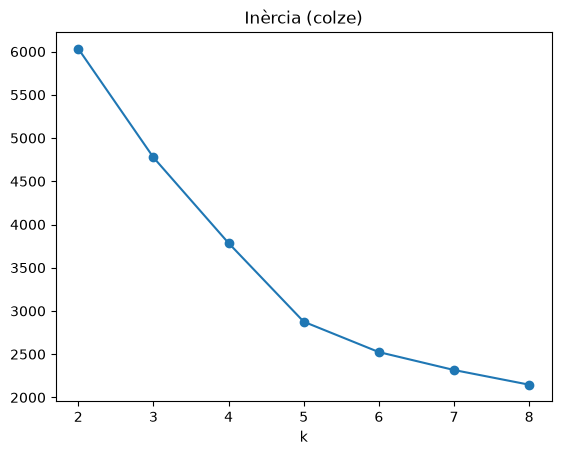

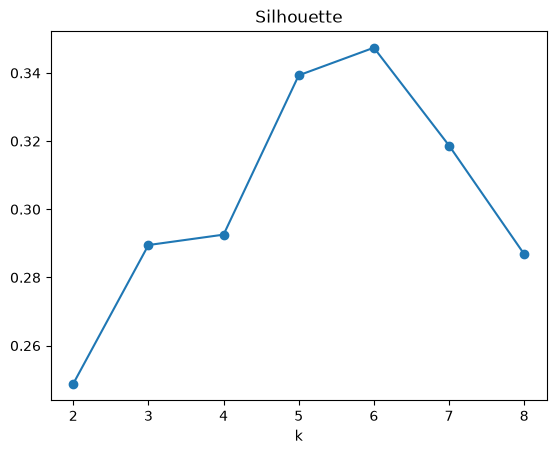

   k   inercia  silhouette
0  2  6033.551       0.249
1  3  4775.883       0.290
2  4  3785.053       0.293
3  5  2875.655       0.339
4  6  2524.193       0.347
5  7  2316.871       0.319
6  8  2147.076       0.287


In [7]:
# Provem K-Means amb k = 2, 3, ... 8 grups
ks = range(2, 9)
inercies = []      # com de junts estan els clients dins del seu grup (menys = millor)
silhouettes = []   # com de separats estan els grups (més = millor)

for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    inercies.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_))

# Gràfic del colze (inèrcia)
plt.plot(ks, inercies, marker='o')
plt.title('Inèrcia (colze)')
plt.xlabel('k')
plt.show()

# Gràfic del silhouette
plt.plot(ks, silhouettes, marker='o')
plt.title('Silhouette')
plt.xlabel('k')
plt.show()

# Taula amb els números
taula = pd.DataFrame({'k': list(ks), 'inercia': inercies, 'silhouette': silhouettes})
print(taula.round(3))

**Elecció: k = 5.** El colze no és clar, però el *silhouette* puja fins a 5–6 i després baixa. Amb k = 4 dos perfils importants queden barrejats (els clients de tiquet molt alt i els d'alta freqüència), i amb k = 6 no apareix cap perfil nou útil. Amb 5 grups cada perfil es pot explicar i accionar. El *silhouette* és modest (≈ 0,34): els grups no estan molt separats, i això cal tindre-ho present quan es diu que un client «és» d'un segment.

In [8]:
# Creem el model definitiu amb k = 5
km = KMeans(n_clusters=5, n_init=10, random_state=42)
km.fit(X)

# Guardem el grup de cada client
d['cluster'] = km.labels_

# Silhouette de cada client (entre -1 i 1; negatiu = potser està en el grup equivocat)
d['silhouette'] = silhouette_samples(X, km.labels_)

print('Silhouette global:', round(silhouette_score(X, km.labels_), 3))

Silhouette global: 0.339


### 2.3 K-Means contra les regles

In [9]:
# Taula que creua les regles amb els grups de K-Means
print(pd.crosstab(d['segment_regles'], d['cluster']))

# Per a calcular el silhouette de les regles, passem les etiquetes a números
codis = d['segment_regles'].astype('category').cat.codes
print('Silhouette de les regles:', round(silhouette_score(X, codis), 3))

cluster              0    1    2    3    4
segment_regles                            
Devolucions altes  168    0   10   17   11
Inactius             0    0  165    0   13
Resta               48  607   39  227  314
Valuosos             0    0    0  296   65
Silhouette de les regles: 0.197


Les regles detecten els extrems (devolucions, inactius), però deixen en «Resta» un grup molt gran i no separen els clients de tiquet molt alt dels de freqüència alta. **K-Means aporta més detall**, tot i que és menys fàcil d'explicar a un tercer.

## 3. Perfils

In [10]:
# Resum de cada grup (valors sense escalar, més fàcils d'entendre)
perfil = d.groupby('cluster').agg(
    clients=('cluster', 'size'),                      # quants clients
    recencia_dies=('days_since_last_order', 'median'),  # dies des de l'última compra
    comandes=('orders_last_12m', 'median'),           # comandes l'últim any
    tiquet_mitja=('avg_order_value', 'median'),       # euros per comanda
    despesa_anual=('annual_spend', 'median'),         # euros l'any
    ratio_devolucions=('returns_ratio', 'mean'),      # percentatge de devolucions
    edat=('age', 'median'),
    antiguitat_mesos=('tenure_months', 'median'),
)

# Percentatge de clients de cada grup
perfil['%'] = perfil['clients'] / len(d) * 100

perfil.round(2)

,clients,recencia_dies,comandes,tiquet_mitja,despesa_anual,ratio_devolucions,edat,antiguitat_mesos,%
cluster,,,,,,,,,
0,216,47.0,4.0,102.76,424.40,0.35,41.0,64.5,10.91
1,607,44.0,3.0,100.10,325.80,0.00,43.0,64.0,30.66
2,214,242.0,2.0,108.32,276.38,0.02,45.0,63.0,10.81
3,540,24.0,9.0,171.75,1473.01,0.07,42.0,63.5,27.27
4,403,48.0,5.0,617.24,2756.76,0.02,47.0,57.0,20.35


In [11]:
# Variables que NO hem usat per a crear els grups, però ajuden a descriure'ls
for c in ['channel_preference', 'bike_interest', 'service_interest']:
    # normalize='index' dona el percentatge dins de cada grup
    taula = pd.crosstab(d['cluster'], d[c], normalize='index') * 100
    print(taula.round(0))
    print()

channel_preference  ecommerce  store
cluster                             
0                        58.0   42.0
1                        57.0   43.0
2                        56.0   44.0
3                        54.0   46.0
4                        56.0   44.0

bike_interest  electric  mountain  service  urban
cluster                                          
0                  15.0      25.0     14.0   46.0
1                  12.0      22.0     27.0   38.0
2                  21.0      25.0     24.0   30.0
3                  25.0      38.0     11.0   26.0
4                  51.0      25.0     11.0   12.0

service_interest  high   low  medium
cluster                             
0                 22.0  39.0    39.0
1                 30.0  32.0    38.0
2                 33.0  28.0    40.0
3                 22.0  40.0    38.0
4                 20.0  39.0    41.0



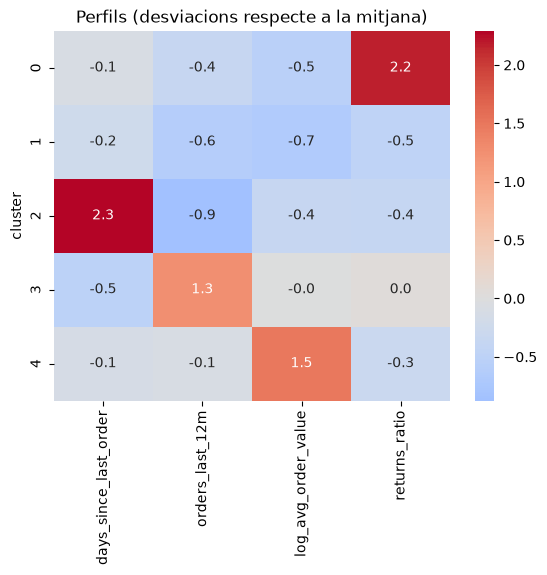

In [12]:
# Mitjana de cada variable escalada, per grup
z = pd.DataFrame(X, columns=vars_cluster)
z['cluster'] = d['cluster'].values
mitjanes = z.groupby('cluster').mean()

# Roig = per damunt de la mitjana, blau = per davall
sns.heatmap(mitjanes, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Perfils (desviacions respecte a la mitjana)')
plt.show()

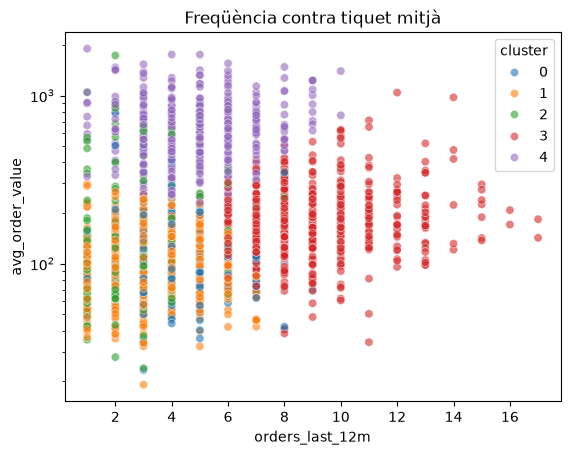

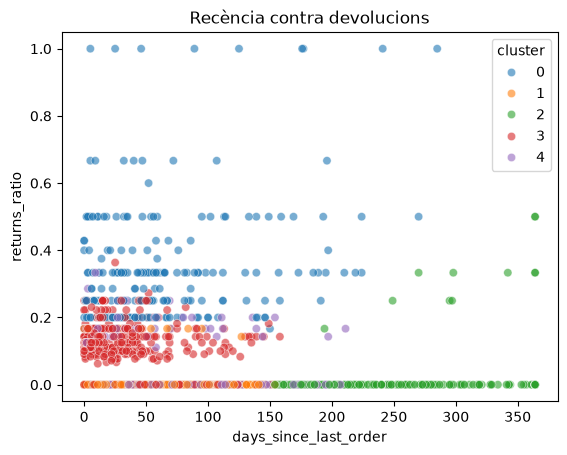

In [13]:
# Freqüència contra tiquet mitjà (cada color és un grup)
sns.scatterplot(data=d, x='orders_last_12m', y='avg_order_value',
                hue='cluster', palette='tab10', alpha=0.6)
plt.yscale('log')   # escala logarítmica perquè hi ha tiquets molt alts
plt.title('Freqüència contra tiquet mitjà')
plt.show()

# Recència contra devolucions
sns.scatterplot(data=d, x='days_since_last_order', y='returns_ratio',
                hue='cluster', palette='tab10', alpha=0.6)
plt.title('Recència contra devolucions')
plt.show()

### 3.1 Casos fronterers

In [14]:
# Clients amb silhouette negatiu (poden estar en el grup equivocat)
negatius = d[d['silhouette'] < 0]
print('Clients amb silhouette negatiu:', len(negatius))
print('Percentatge:', round(len(negatius) / len(d) * 100, 1))

# Silhouette mitjà de cada grup
print(d.groupby('cluster')['silhouette'].mean().round(2))

# Els 5 clients més fronterers (silhouette més baix)
cols_veure = ['customer_id', 'cluster', 'days_since_last_order',
              'orders_last_12m', 'avg_order_value', 'returns_ratio', 'silhouette']
d.sort_values('silhouette').head(5)[cols_veure]

Clients amb silhouette negatiu: 58
Percentatge: 2.9
cluster
0    0.24
1    0.43
2    0.29
3    0.29
4    0.35
Name: silhouette, dtype: float64


,customer_id,cluster,days_since_last_order,orders_last_12m,avg_order_value,returns_ratio,silhouette
1417,C01418,2,161.0,4,82.21,0.00,-0.099644
1658,C01659,0,27.0,4,407.12,0.25,-0.079776
588,C00589,0,84.0,8,122.52,0.25,-0.079318
564,C00565,3,31.0,6,179.59,0.00,-0.077815
1415,C01416,3,26.0,6,177.38,0.00,-0.075661


Quasi tots els clients tenen un perfil clar, però no tots. Els que tenen el *silhouette* baix estan a mig camí de dos grups. Per exemple, clients amb una ràtio de devolucions just al voltant de 0,25, o de freqüència mitjana entre dos perfils. Són poc freqüents (≈ 3 % amb *silhouette* negatiu), però l'empresa no els hauria de tractar com a membres segurs d'un segment.

### 3.2 Noms dels perfils

In [15]:
# Posem nom a cada grup segons la taula de perfils de dalt
# (comandes, tiquet mitjà, recència i devolucions)
# Si en local els números no coincideixen, canvia'ls ací
noms = {
    0: 'Devolucions altes',
    1: 'Ocasionals de tiquet baix',
    2: 'Inactius',
    3: 'Fidels freqüents',
    4: 'Tiquet alt',
}

# Afegim una columna amb el nom del perfil
d['perfil'] = d['cluster'].map(noms)

# Quants clients té cada perfil
d['perfil'].value_counts()

perfil
Ocasionals de tiquet baix    607
Fidels freqüents             540
Tiquet alt                   403
Devolucions altes            216
Inactius                     214
Name: count, dtype: int64

### 3.3 Interpretació

Els valors són orientatius (medianes de la taula de dalt).

| Perfil | Mida | Comportament | Què el diferencia |
|---|---|---|---|
| **Fidels freqüents** | ≈ 27 % | Compren molt (≈ 9 comandes/any), han comprat fa poc (≈ 24 dies), tiquet mitjà (≈ 170 €) | Més freqüència i més recència. Mostren més interés per mountain i electric |
| **Tiquet alt** | ≈ 20 % | Pocs encàrrecs (≈ 5) però molt cars (≈ 620 € de mitjana), la despesa anual més alta (≈ 2.750 €) | La major part s'interessa per electric (≈ 50 %), i són una mica més majors i amb menys antiguitat |
| **Ocasionals de tiquet baix** | ≈ 31 % | Poques comandes (≈ 3), tiquet ≈ 100 €, cap devolució | Són el grup més gran i el que menys gasta (≈ 330 €/any) |
| **Inactius** | ≈ 11 % | Fa molt que no compren (≈ 240 dies), només ≈ 2 comandes | Gairebé són clients perduts |
| **Devolucions altes** | ≈ 11 % | Ràtio de devolucions ≈ 0,35 amb una despesa baixa (≈ 420 €) | Es distingeixen només per les devolucions |

**Límits:** el canal preferit i l'interés per serveis són quasi iguals en tots els grups, així que no ajuden a diferenciar. Esta fotografia és d'un sol dia: no sabem si un client canvia de perfil amb el temps. I no hi ha cap etiqueta correcta: amb una altra k o un altre escalat els grups canviarien una mica.

## 4. Taula de segments i accions comercials

**NOTA**

Aquesta part és una explicació del següent `Jupyter Notebook`: [Taula de segments i accions comercials](../evidencies/Taula_de_segments_i_accions_comercials.ipynb).

L'explicació contindra xicotets blocs de codi per a que n'hi haga una visualització de com funciona cada cosa, però com s'ha esmentat abans el notebook és troba en l'enllaç anterior.

### 4.1 Taula de segmentació

Per a fer la taula de segments primer hem de segmentar, en este cas anem a segmentar els clients en estes categories segons el que gasten (`annual_spend`) i el temps que porten desde la última venda (`days_since_last_order`), en este cas sí el client porta més de 90 dies sense comprar.

In [44]:
# Creem una segmentació de valor basats en el que gasten els clients (sales_history.annual_spend)
df["segment_valor"] = pd.qcut(df["annual_spend"], q=3, labels=["Baix", "Mitjà", "Alt"])

# Definim si el client està en risc (més de 90 dies sense comprar)
df["estat_client"] = np.where(df["days_since_last_order"] > 90, "Risc", "Actiu")

df["segment_comercial"] = (df["segment_valor"].astype(str) + "_" + df["estat_client"])

Ja amb els clients segmentats anem a agafar les campanyes (`campaign`) del fitxer `sales_history.csv` per a classificar els clients en quina campanya compren més:

In [45]:
sales = pd.read_csv("../dades/sales_history.csv")

# Extraiem les campanyes del fitxer de vendes
accions_disponibles = sales["campaign"].unique()

Ara agafem un número pseudoaleatori (`seed`) per a que no altere el resultat i agafem una acció comercial de forma aleatòria.

In [46]:
np.random.seed(42)
df["accio_comercial"] = np.random.choice(accions_disponibles, size=len(df))

Seguidament mirem els clients segmentats amb un gast elevat i mirem si la campanya es `black_friday` o bé `christmas`:

In [47]:
es_client_vip = df["segment_valor"] == "Alt"
es_campanya_alta = df["accio_comercial"].isin(["black_friday", "christmas"])

Ací mirem amb els valors creats anteriormenr veiem si el client va respondre (`1`) o no (`0`):

In [48]:
prob_resposta = np.where(es_client_vip & es_campanya_alta, 0.7, 0.15)
df["respongut"] = [np.random.choice([0, 1], p=[1 - p, p]) for p in prob_resposta]

Per últim crearem a una taula creuada (`matriu`) assignant de forma simulada o històrica quina acció s'ha aplicat a cada client.

In [49]:
matriu_resum = (
    df.groupby(["segment_comercial", "accio_comercial"])["respongut"]
    .agg(Total_Clients="count", Taxa_Resposta="mean")
    .reset_index()
)

### 4.2 Accions comercials

#### 4.2.1 Creació del model

Per a les accions comercials anem a crear un model de classificació que ens permetrà predir quin retorn o probabilitat d'èxit tindrem si apliquem una acció concreta a un client determinat.

In [50]:
# Importació de llibreries de sklearn necessaries

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

Per a això primer anem a agafar algunes columnes que ens serviran per a entrenar al model.

In [ ]:
features = ["segment_comercial", "accio_comercial", "age", "annual_spend", "avg_order_value", "orders_last_12m"]
X = df[features]
y = df.loc[X.index, "respongut"]

Seguidament anem a codificar les variables categòriques (Ex: `spring` -> 0) i conservem les variables numèriques.

In [ ]:
preprocessor = ColumnTransformer(transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), ["segment_comercial", "accio_comercial"])] ,remainder="passthrough")

X_processed = preprocessor.fit_transform(X)

Seguidament separarem el dataset en dades d'entrenament i de test de la següent forma:

- Entrenament: `80%`
- Test: `20%`

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

Per últim entrenarem al model amb les dades d'entrenament.

In [ ]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

#### 4.2.2 Posada en marxa del model

Per a probar el model anem a agafar al primer client per a vore com va el model

In [ ]:
client_mostra = df.iloc[[0]].copy()

Ara anem a simular l'avaluació de totes les accions possibles que és poden fer en eixe client

In [ ]:
simulacio_accions = []
for accio in accions_disponibles:
    temp = client_mostra.copy()
    temp["accio_comercial"] = accio
    simulacio_accions.append(temp)

df_simulacio = pd.concat(simulacio_accions, ignore_index=True)

Per últim anem a predeïr la probabilitat d'exit del model amb eixe client en específic:

In [ ]:
X_simulacio = preprocessor.transform(df_simulacio[features])
probabilitats = model.predict_proba(X_simulacio)[:, 1]

df_simulacio["probabilitat_exit"] = probabilitats
recomanacio = df_simulacio.sort_values(by="probabilitat_exit", ascending=False).iloc[0]

## 5. Comparativa de models de la setmana 3 i decisió final